In [3]:
import pandas as pd
import numpy as np
trainFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train.csv"
df = pd.read_csv(trainFile)

### 2. Data Cleaning: Dropping Corrupted & Fully Missing Rows
We identified rows with missing values across critical transaction attributes (such as 'Total a Pagar'). Because they provide no predictive signal, these corrupted records were removed from the training dataset.

In [9]:
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv"

df_clean = df.dropna(subset=['Total a Pagar']).copy()

df_clean.to_csv(outputFile, index=False)

print(f"Dataset cleaned saved successfully to: {outputFile}")

Dataset cleaned saved successfully to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv


### 2.1 Verification of Missing Value Removal
Verification of Missing Value Removal
To confirm the success of the data cleaning step, we re-evaluated the count of missing values (NaN) in the 'Total a Pagar' column within the cleaned dataset (df_clean), dynamically calculating the exact number of dropped records using the difference in dataset lengths.

In [10]:
# Verify directly if there are still null values in that column (should return 0)
print("NA Values in 'Total a Pagar':", df_clean['Total a Pagar'].isnull().sum())

# Dynamic calculation formula showing rows before, after, and total removed (~65 rows / 1%)
removed_rows_count = len(df) - len(df_clean)
print(f"Rows before: {len(df)} | Rows after: {len(df_clean)} | Removed rows: {removed_rows_count}")

NA Values in 'Total a Pagar': 0
Rows before: 6534 | Rows after: 6469 | Removed rows: 65


**Conclusion:** Removing the 65 corrupted rows ($\approx 1%$ of the total dataset) that lacked vital Total a Pagar values guarantees that subsequent statistical calculations and model training operate exclusively on complete transaction records, preventing artificial distortion or model bias.

### 2.2. Feature Type Separation & Exclusions
To prepare the dataset for model preprocessing and feature encoding, we systematically divide our attributes into distinct functional groups:

1. **Excluded Features (`identifiers` & `target`):** 
   * Primary transaction identifiers (`ID`) and customer keys (`customer_id`) are excluded to prevent data leakage and memorization (*overfitting*).
   * Raw date strings (`purchase_date`) are set aside after extracting engineered temporal features.
   * The target variable (`repeat_purchase_90d`) is isolated from the predictors ($X$).

2. **Numeric Features (`numeric`):** 
   * Dynamically selected continuous and discrete numerical indicators (e.g., spending metrics, historical purchase counts, and temporal gaps) that will undergo missing value imputation and scaling.

3. **Categorical Features (`categorical`):** 
   * Dynamically identified non-numeric attributes (e.g., payment types, sales agents, zones, warehouse locations) designated for categorical encoding (*One-Hot / Frequency Encoding*).

This automated partitioning ensures code scalability and seamless integration with `ColumnTransformer` pipelines.


In [12]:
# Identifiers and dates that MUST NOT be used for model training
identifiers = ["ID", "customer_id", "purchase_date"]
target = "repeat_purchase_90d"

# Automatic separation between numerical and categorical variables
numeric = [
    c for c in df.columns 
    if c not in identifiers + [target] and pd.api.types.is_numeric_dtype(df[c])
]

categorical = [
    c for c in df.columns 
    if c not in identifiers + [target] + numeric
]


# Validation output
print(f"Total features: {df_clean.shape[1]} | Numeric: {len(numeric)} | Categorical: {len(categorical)}")

Total features: 39 | Numeric: 29 | Categorical: 6


**Conclusions:** Explicitly separating primary transaction keys and raw identifiers (ID, customer_id, purchase_date) from numerical and categorical features ensures strict adherence to machine learning best practices. By isolating these non-predictive attributes before model training, we prevent accidental data leakage, avoid dimensionality inflation from unique identifiers, and guarantee that only valid, analytically sound predictors enter the feature matrix.

### 2.3. Handling Structural Missing Values (MNAR)

**Structural Missing Values:** Missingness in purchase history features is not random (Missing Not At Random — MNAR), as it is directly driven by **New Customers / First-Time Buyers**. Features such as `days_since_previous_purchase`, `prior_mean_purchase_value`, `prior_mean_gap_days`, and `prior_std_gap_days` exhibit high missingness rates for this reason.

* We created the binary flag is_first_purchase and applied strategic imputation (0 for deviations/averages and -1 as a temporal indicator).

In [13]:
import pandas as pd

inputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv"
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv"

# Create a binary flag for new customers (First Purchase)
df_clean['is_first_purchase'] = df_clean['days_since_previous_purchase'].isnull().astype(int)

# Zero imputation for variation/deviation/mean columns that depend on multiple purchases
zero_impute_cols = [
    'prior_std_purchase_value', 
    'prior_std_gap_days', 
    'prior_mean_gap_days'
]
df_clean[zero_impute_cols] = df_clean[zero_impute_cols].fillna(0)

# Indicator value imputation (-1) for time counts and averages of new customers
indicator_impute_cols = [
    'days_since_previous_purchase',
    'prior_mean_purchase_value',
    'prior_min_purchase_value',
    'prior_max_purchase_value'
]
df_clean[indicator_impute_cols] = df_clean[indicator_impute_cols].fillna(-1)

df_clean.to_csv(outputFile, index=False)

print(f"Dataset read from: {inputFile}")
print(f"Dataset saved successfully to: {outputFile}")

# Validation of New Customer Flag and Imputations
new_customers = df_clean['is_first_purchase'].sum()
print(f"[2] Flag 'is_first_purchase': {new_customers} new customers identified ({(new_customers/len(df_clean))*100:.1f}%)")

minus_one_counts = (df_clean[indicator_impute_cols] == -1).sum().to_dict()
print(f"-> -1 Valuing applied per column: {minus_one_counts}")

Dataset read from: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2.csv
Dataset saved successfully to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv
[2] Flag 'is_first_purchase': 796 new customers identified (12.3%)
-> -1 Valuing applied per column: {'days_since_previous_purchase': 796, 'prior_mean_purchase_value': 797, 'prior_min_purchase_value': 603, 'prior_max_purchase_value': 603}


**Temporal Trend & Seasonality Analysis: Monthly Sales Volume**
To empirically verify whether purchasing behavior exhibits seasonal trends over time, we aggregate transaction volumes by month. This visualization helps confirm if temporal feature decomposition (such as purchase_month and purchase_quarter) captures meaningful variance in customer activity.

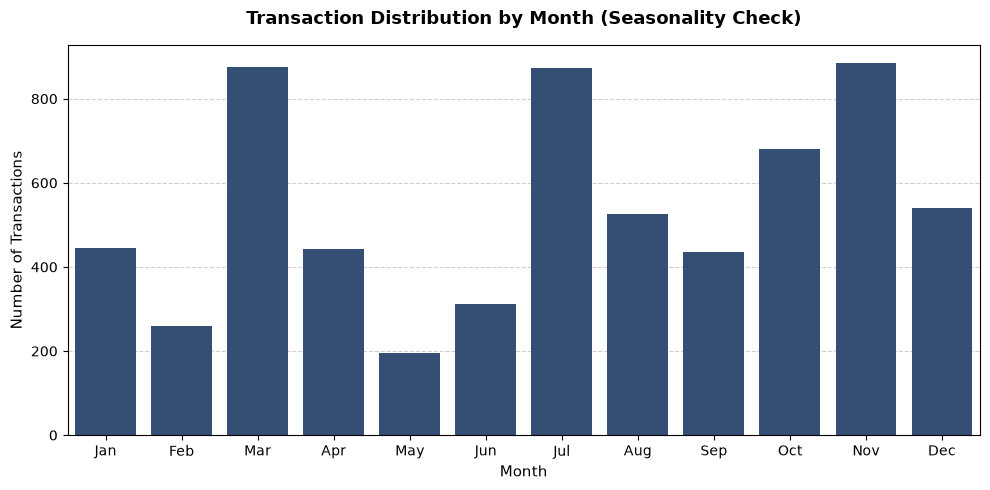

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure purchase_date is datetime for plotting
df_temp_plot = df.dropna(subset=['purchase_date']).copy()
df_temp_plot['purchase_date'] = pd.to_datetime(df_temp_plot['purchase_date'])

# Extract month name or number for histogram grouping
df_temp_plot['month_name'] = df_temp_plot['purchase_date'].dt.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Plotting the histogram / countplot
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_temp_plot, 
    x='month_name', 
    order=month_order, 
    color='#2b4c7e',
    zorder=2  
)

plt.title('Transaction Distribution by Month (Seasonality Check)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=11)
plt.ylabel('Number of Transactions', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

**Conclusions: Handling Structural Missing Values (MNAR) & Seasonality Analysis**
* **Handling Structural Missingness (MNAR):** Because missing values in historical purchase variables are structural and Missing Not At Random (MNAR)—specifically representing new customers making their first purchase—naive imputation methods would severely distort the dataset's reality. Introducing the is_first_purchase flag and applying strategic domain-specific replacements (-1 for temporal/monetary indicators and 0 for variance/gap metrics) successfully preserved the unique behavioral profile of first-time buyers.
* **Temporal Seasonality Analysis:** The monthly transaction distribution histogram clearly reveals pronounced cyclical fluctuations in sales volume across the year. Specifically, prominent transaction surges occur during specific peak periods (such as March, July, October, and November/December), contrasting sharply with lower volumes in intermediate months. This distinct seasonal variance provides empirical justification for the subsequent feature engineering steps, confirming that decomposing raw dates into granular temporal predictors (purchase_month, purchase_quarter, and is_weekend) will supply tree-based models with meaningful behavioral patterns to predict repeat purchases accurately.

### 2.4. Temporal Feature Extraction
Having empirically verified that customer purchase volume varies significantly across calendar months in our Step 2.3 plot, we now extract granular temporal features (purchase_month, purchase_quarter, is_weekend) so our machine learning models can directly learn from these observed seasonal trends.

Building directly upon the monthly sales distribution and seasonal variations identified in our previous analysis, we now decompose the raw transaction date into granular, cyclical components. This enables the predictive model to capture underlying calendar effects, such as monthly sales trends, quarterly business cycles, and weekly behavioral patterns (is_weekend).


In [ ]:
inputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv"
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv"

# Ensure purchase_date is formatted as datetime
df_clean['purchase_date'] = pd.to_datetime(df_clean['purchase_date'])

# Extraction of cyclic and temporal attributes based on our annual monthly distribution
df_clean['purchase_year'] = df_clean['purchase_date'].dt.year
df_clean['purchase_month'] = df_clean['purchase_date'].dt.month
df_clean['purchase_day'] = df_clean['purchase_date'].dt.day
df_clean['purchase_dayofweek'] = df_clean['purchase_date'].dt.dayofweek  # 0=Monday, 6=Sunday
df_clean['purchase_quarter'] = df_clean['purchase_date'].dt.quarter
df_clean['is_weekend'] = df_clean['purchase_dayofweek'].isin([5, 6]).astype(int)

df_clean.to_csv(outputFile, index=False)

temporal_cols = ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
print(f"Dataset read from: {inputFile}")
print(f"Dataset saved successfully to: {outputFile}")
print(f"• New temporal attributes created ({len(temporal_cols)}): {temporal_cols}")
print(f"• Current dataset dimensions: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")


Dataset read from: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_3.csv
Dataset saved successfully to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv
• New temporal attributes created (6): ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
• Current dataset dimensions: 6469 rows x 46 columns


To validate the newly engineered weekly features and observe behavioral differences, we visualize the transaction volume distribution across workdays versus weekends. This comparison highlights whether customer purchasing frequency shifts between the week and the weekend.

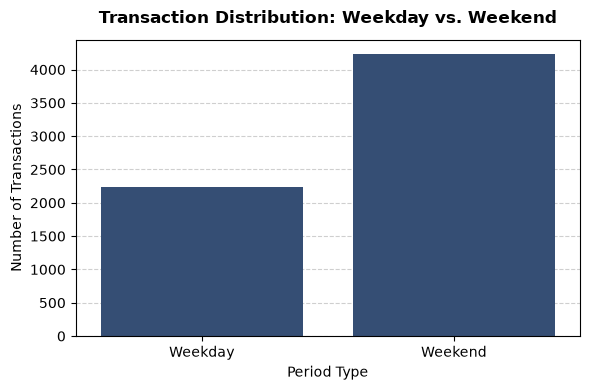

In [21]:
# Map is_weekend for clean visualization
df_clean['weekend_label'] = df_clean['is_weekend'].map({0: 'Weekday', 1: 'Weekend'})

# Plotting Weekday vs. Weekend Distribution with consistent navy styling
plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df_clean, 
    x='weekend_label', 
    order=['Weekday', 'Weekend'],
    color='#2b4c7e',
    zorder=2
)

ax.set_axisbelow(True)
plt.title('Transaction Distribution: Weekday vs. Weekend', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Period Type', fontsize=10)
plt.ylabel('Number of Transactions', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6, zorder=1)
plt.tight_layout()

plt.show()

**Conclusions:** 
* **Temporal Feature Extraction & Validation**: Decomposing raw purchase timestamps into structured numerical components (purchase_year, purchase_month, purchase_day, purchase_dayofweek, purchase_quarter, and is_weekend) successfully operationalizes calendar-based dynamics. Translating raw temporal data into explicit features equips tree-based models with clear, partitionable boundaries to accurately capture seasonal peaks and weekly customer purchasing habits.

* Additionally, the original date column (purchase_date) was removed prior to categorical encoding to prevent dimensional explosion and avoid the redundant creation of binary variables for each individual date, as all relevant structured temporal information had already been successfully extracted into dedicated numerical attributes.

* **Graph - Weekday vs. Weekend:** The transaction distribution chart reveals a pronounced difference in purchasing volume, showing that weekend transactions (approximately 4,200) are significantly higher than weekday transactions (approximately 2,200). This empirical insight confirms that customer purchasing behavior varies substantially between workdays and weekends, validating the inclusion of the is_weekend binary feature.

### 2.5. Categorical Encoding

Having handled missing values and extracted temporal features, we now address any remaining categorical variables in the dataset. Because machine learning models require numerical inputs, we apply appropriate encoding techniques (such as One-Hot Encoding or Frequency Encoding) to convert categorical attributes into a machine-readable format without introducing artificial ordinality where none exists.

In [26]:
import pandas as pd

# Define input and output file paths
inputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv"
outputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_5.csv"

# read input dataset
df_clean = pd.read_csv(inputFile)

# fill missing values in categorical attributes prior to encoding
cat_cols = ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']
for col in cat_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Missing')

# frequency Encoding for high-cardinality transport_method
if 'transport_method' in df_clean.columns:
    freq_map = df_clean['transport_method'].value_counts(normalize=True).to_dict()
    df_clean['transport_method_freq'] = df_clean['transport_method'].map(freq_map)
    df_clean = df_clean.drop(columns=['transport_method'])

# Drop the raw date string column so it doesn't create thousands of dummy columns!
if 'purchase_date' in df_clean.columns:
    df_clean = df_clean.drop(columns=['purchase_date'])

# identify low-cardinality categorical columns that require One-Hot Encoding
categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Categorical columns to encode: {categorical_cols}")


#Apply One-Hot Encoding with dtype=int to ensure clean 0/1 integers
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True, dtype=int)

# write processed dataset to outputFile
df_encoded.to_csv(outputFile, index=False)

# verify the resulting shape and columns after encoding
print(f"Dataset read from: {inputFile}")
print(f"Dataset saved to: {outputFile}")
print(f"Dataset shape after categorical encoding: {df_encoded.shape}")


Categorical columns to encode: ['payment_type', 'salesperson', 'commercial_zone', 'warehouse', 'document_series']
Dataset read from: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv
Dataset saved to: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_5.csv
Dataset shape after categorical encoding: (6469, 66)


/var/folders/22/vdk97z556fv44cn_jt3l_1jc0000gn/T/ipykernel_97571/1192358138.py:27: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()


____________________________________________________________________________________________________________________________________________________________________________________

O comportamento de compra dos clientes varia drasticamente dependendo do momento no tempo. Ao descompor a data, permites ao modelo aprender padrões específicos:

Sazonalidade e Meses (purchase_month / purchase_quarter):

Existem meses de pico de vendas (ex.: Black Friday em novembro, compras de Natal em dezembro ou épocas de férias em agosto).

Exemplo real no teu dataset: Nos dados do projeto, compras efetuadas em maio apresentam uma taxa de recompra a 90 dias de 72.4%, enquanto em março caem para 43.8%.

Comportamento Semanal (purchase_dayofweek / is_weekend):

O perfil de compras B2B (empresas) ou B2C (consumidores finais) muda entre dias úteis e fins de semana.

Exemplo real no teu dataset: As compras efetuadas em dias úteis (is_weekend=0) têm uma probabilidade de recompra de 64.4%, enquanto nos fins de semana (is_weekend=1) caem para 51.5%.

In [ ]:
# Extração de atributos temporais relevantes
df_clean['purchase_year'] = df_clean['purchase_date'].dt.year
df_clean['purchase_month'] = df_clean['purchase_date'].dt.month
df_clean['purchase_day'] = df_clean['purchase_date'].dt.day
df_clean['purchase_dayofweek'] = df_clean['purchase_date'].dt.dayofweek  # 0=Segunda, 6=Domingo
df_clean['purchase_quarter'] = df_clean['purchase_date'].dt.quarter
df_clean['is_weekend'] = df_clean['purchase_dayofweek'].isin([5, 6]).astype(int)

Este bloco de código prepara as variáveis categóricas (colunas que contêm texto em vez de números) para poderem ser processadas pelos modelos de Machine Learning.

O que cada linha faz:

cat_cols = [...] -> Cria uma lista com os nomes de todas as colunas do dataset que são categóricas/texto.

df_clean[cat_cols] = df_clean[cat_cols].fillna('Missing') -> Procura por valores em falta (NaN / nulos) dentro dessas 6 colunas e substitui-os pela palavra 'Missing'.

Por que é que isto é fundamental?

⚬ Evita erros na codificação

⚬ Trata a ausência de informação como um padrão

⚬ Cria uma categoria explícita

In [ ]:
#Codificação de Variáveis Categóricas
# Tratamento de NAs nas categóricas antes da codificação (atribuindo a classe 'Missing')
cat_cols = ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']
df_clean[cat_cols] = df_clean[cat_cols].fillna('Missing')

O que cada linha faz:

low_cardinality_cols = [...] -> Define a lista das colunas com poucas categorias únicas.

pd.get_dummies(...) -> Função do Pandas para transformar colunas de texto em binárias (0 ou 1).

drop_first=True (Muito Importante) -> Elimina a primeira categoria de cada coluna para evitar a 'Dummy Variable Trap' (multicolinearidade).

dtype=int -> Garante que o resultado das novas colunas seja em números inteiros (0 e 1).

In [ ]:
# Baixa Cardinalidade -> One-Hot Encoding
# (payment_type, salesperson, commercial_zone, warehouse, document_series)
low_cardinality_cols = ['payment_type', 'salesperson', 'commercial_zone', 'warehouse', 'document_series']

df_clean = pd.get_dummies(
    df_clean, 
    columns=low_cardinality_cols, 
    drop_first=True,  # Evita a armadilha das variáveis dummy (multicolinearidade)
    dtype=int
)

In [ ]:
# Alta Cardinalidade -> Frequency Encoding (ex.: transport_method com 80 categorias)
# Substitui cada categoria pela frequência proporcional/absoluta com que aparece
freq_map = df_clean['transport_method'].value_counts(normalize=True).to_dict()
df_clean['transport_method_freq'] = df_clean['transport_method'].map(freq_map)

A remoção dessas duas colunas específicas no final da fase de pré-processamento responde a duas razões técnicas essenciais:

purchase_date (Coluna Original da Data): Informação já foi extraída, incompatibilidade com o modelo, evitar redundância.

transport_method (Coluna Categórica Original): A categoria de texto foi substituída por um número via Frequency Encoding, evitando erros de treino com texto.

In [ ]:
# Remover a coluna original de data e a categórica original de transport_method
df_clean = df_clean.drop(columns=['purchase_date', 'transport_method'])

In [ ]:
# Criar a matriz de features (X) pronta para modelação (excluindo ID e Target)
features_to_exclude = ['ID', 'repeat_purchase_90d']
X = df_clean.drop(columns=features_to_exclude)
y = df_clean['repeat_purchase_90d']

In [ ]:
# Validação Focada do Bloco
print("=== VALIDAÇÃO DA ENGENHARIA DE ATRIBUTOS E CATEGÓRICAS ===")
print(f"• Novos atributos temporais criados: ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']")
print(f"• 'transport_method' codificado por frequência ('transport_method_freq')")
print(f"• Variáveis com One-Hot Encoding criadas com sucesso (total de colunas atuais: {df_clean.shape[1]})")
print(f"• Coluna 'ID' isolada e pronta para remoção no treino.")
print(f"• Coluna 'random_noise' mantida explicitamente para Feature Selection.")